In [1]:
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import catboost

In [3]:
df = pd.read_csv("Data/data_kern_ratios.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3099 entries, 0 to 3098
Data columns (total 54 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3099 non-null   float64
 1   Al                        3099 non-null   float64
 2   Si                        3099 non-null   float64
 3   P                         3099 non-null   float64
 4   S                         3099 non-null   float64
 5   K                         3099 non-null   float64
 6   Ca                        3099 non-null   float64
 7   Ti                        3099 non-null   float64
 8   Mn                        3099 non-null   float64
 9   Fe                        3099 non-null   float64
 10  Ni                        3099 non-null   float64
 11  Cu                        3099 non-null   float64
 12  Zn                        3099 non-null   float64
 13  Se                        3099 non-null   float64
 14  Rb      

In [5]:
df['Strat'].value_counts().sort_index()

Strat
0     430
1     155
2     193
3     270
4     236
5     145
6     150
7     191
8     392
9     491
10    298
11    148
Name: count, dtype: int64

**Эксперимент 6**

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по элементам после замены нулей**

In [8]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9822
F1 macro (val):   0.4485
Gap (train-val):  0.5338

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9808    0.4048    0.5730       126
           1     0.2759    0.3137    0.2936        51
           2     0.2295    0.6087    0.3333        46
           3     0.7273    0.6667    0.6957        72
           4     0.6905    0.6444    0.6667        45
           5     0.0000    0.0000    0.0000         7
           6     0.4400    0.2558    0.3235        43
           7     0.4286    0.3243    0.3692        37
           8     0.3333    0.2400    0.2791        50
           9     0.4797    0.8987    0.6256        79
          10     0.9000    0.5000    0.6429        72
          11     0.5789    0.5789    0.5789        19

    accuracy                    

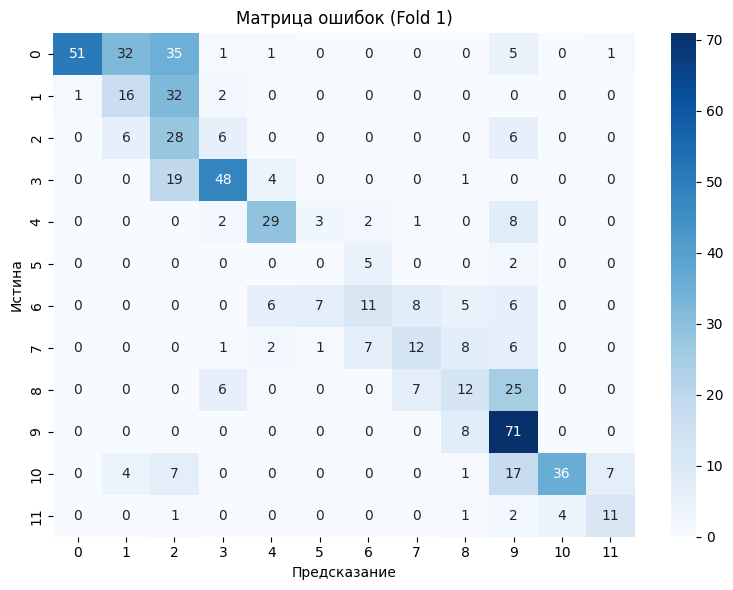

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9863
F1 macro (val):   0.6692
Gap (train-val):  0.3171

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.7978    0.9103    0.8503        78
           1     0.8182    0.4091    0.5455        44
           2     0.6429    0.7200    0.6792        50
           3     0.8209    0.7639    0.7914        72
           4     0.6458    0.8052    0.7168        77
           5     0.5172    0.4054    0.4545        37
           6     0.4375    0.2500    0.3182        28
           7     0.4412    0.5357    0.4839        28
           8     0.6386    0.6625    0.6503        80
           9     0.7838    0.8208    0.8018       106
          10     0.8056    0.8056    0.8056        36
          11     1.0000    0.8750    0.9333        24

    accuracy                    

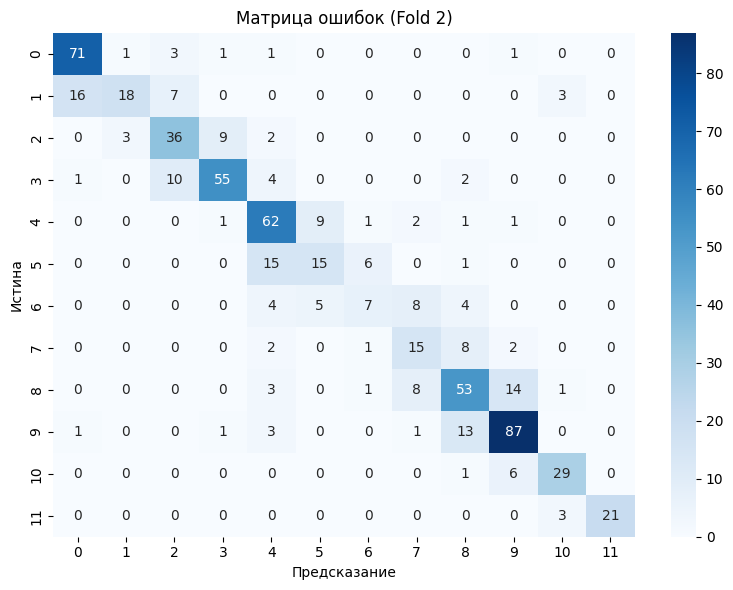

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9845
F1 macro (val):   0.5662
Gap (train-val):  0.4183

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9306    0.9710    0.9504        69
           1     0.5000    0.4286    0.4615        14
           2     0.4737    0.6750    0.5567        40
           3     0.6304    0.5800    0.6042        50
           4     0.7105    0.5000    0.5870        54
           5     0.5909    0.3611    0.4483        36
           6     0.3000    0.5000    0.3750        18
           7     0.3810    0.2105    0.2712        38
           8     0.5205    0.5067    0.5135        75
           9     0.6091    0.7701    0.6802        87
          10     0.6027    0.7213    0.6567        61
          11     0.7692    0.6250    0.6897        64

    accuracy                    

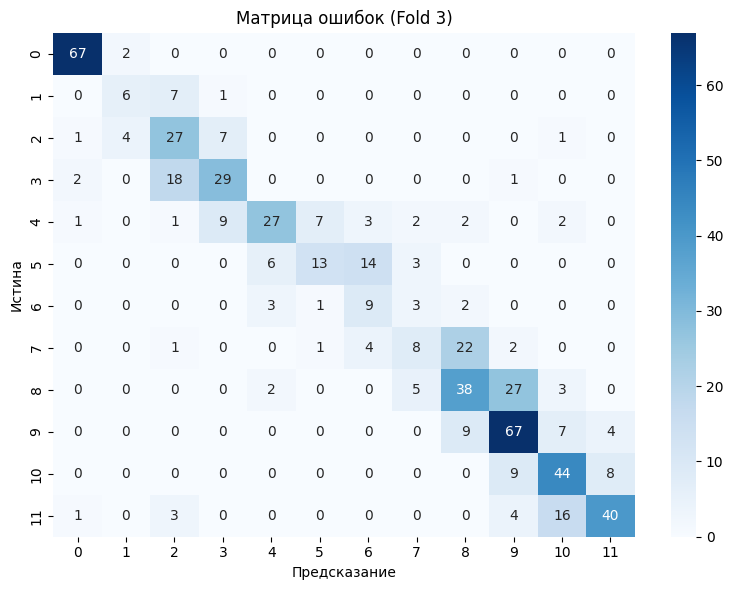

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9806
F1 macro (val):   0.5869
Gap (train-val):  0.3937

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9684    0.9583    0.9634        96
           1     0.7500    0.4737    0.5806        19
           2     0.7027    0.9286    0.8000        28
           3     0.7879    0.8125    0.8000        32
           4     0.4528    0.7742    0.5714        31
           5     0.3000    0.2667    0.2824        45
           6     0.4400    0.2683    0.3333        41
           7     0.3333    0.1333    0.1905        60
           8     0.5583    0.5826    0.5702       115
           9     0.6147    0.7882    0.6907        85
          10     0.8000    0.9302    0.8602        43
          11     1.0000    0.2500    0.4000         4

    accuracy                    

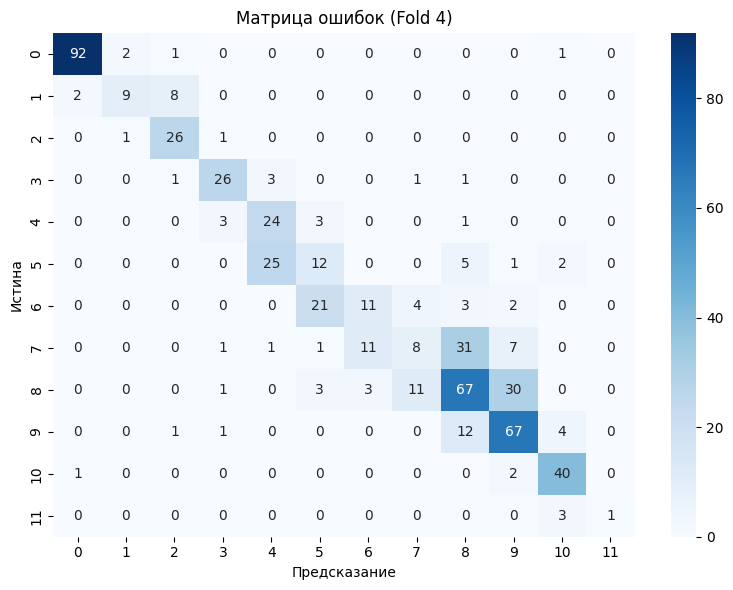

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9811
F1 macro (val):   0.5583
Gap (train-val):  0.4228

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8235    0.9180    0.8682        61
           1     0.6667    0.4444    0.5333        27
           2     0.4444    0.5517    0.4923        29
           3     0.8222    0.8409    0.8315        44
           4     0.6765    0.7931    0.7302        29
           5     0.3333    0.4000    0.3636        20
           6     0.1429    0.1000    0.1176        20
           7     0.3077    0.2857    0.2963        28
           8     0.3621    0.5833    0.4468        72
           9     0.6404    0.5448    0.5887       134
          10     0.8654    0.5233    0.6522        86
          11     0.7500    0.8108    0.7792        37

    accuracy                    

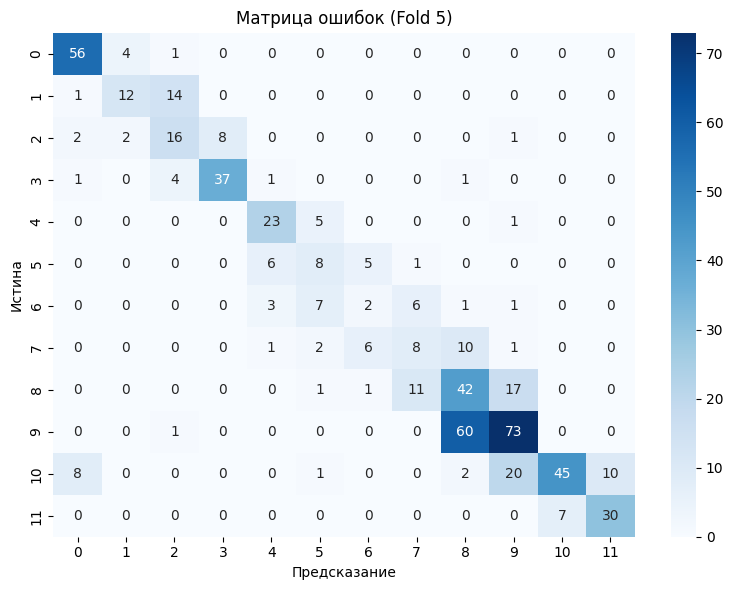

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4485
  Fold 2: F1_macro = 0.6692
  Fold 3: F1_macro = 0.5662
  Fold 4: F1_macro = 0.5869
  Fold 5: F1_macro = 0.5583

  Средний F1 macro: 0.5658 ± 0.0790
  Средний gap: 0.4171 ± 0.0778

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.8963    0.7837    0.8362       430
           1     0.5000    0.3935    0.4404       155
           2     0.4318    0.6891    0.5309       193
           3     0.7588    0.7222    0.7400       270
           4     0.6274    0.6992    0.6613       236
           5     0.3810    0.3310    0.3542       145
           6     0.3636    0.2667    0.3077       150
           7     0.3835    0.2670    0.3148       191
           8     0.4953    0.5408    0.5171       392
           9     0.6166    0.7434    0.6741       491
          10     0.7729    0.6510    0.7067       298
          11     0.7744    0.6959    0.7331       148

    accuracy      

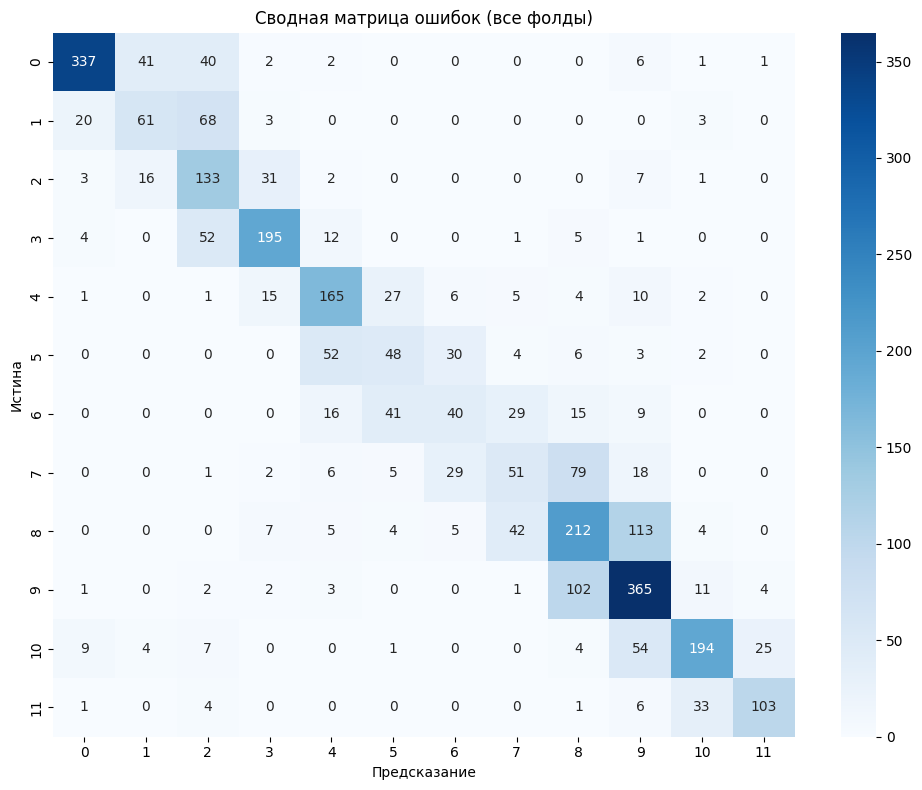

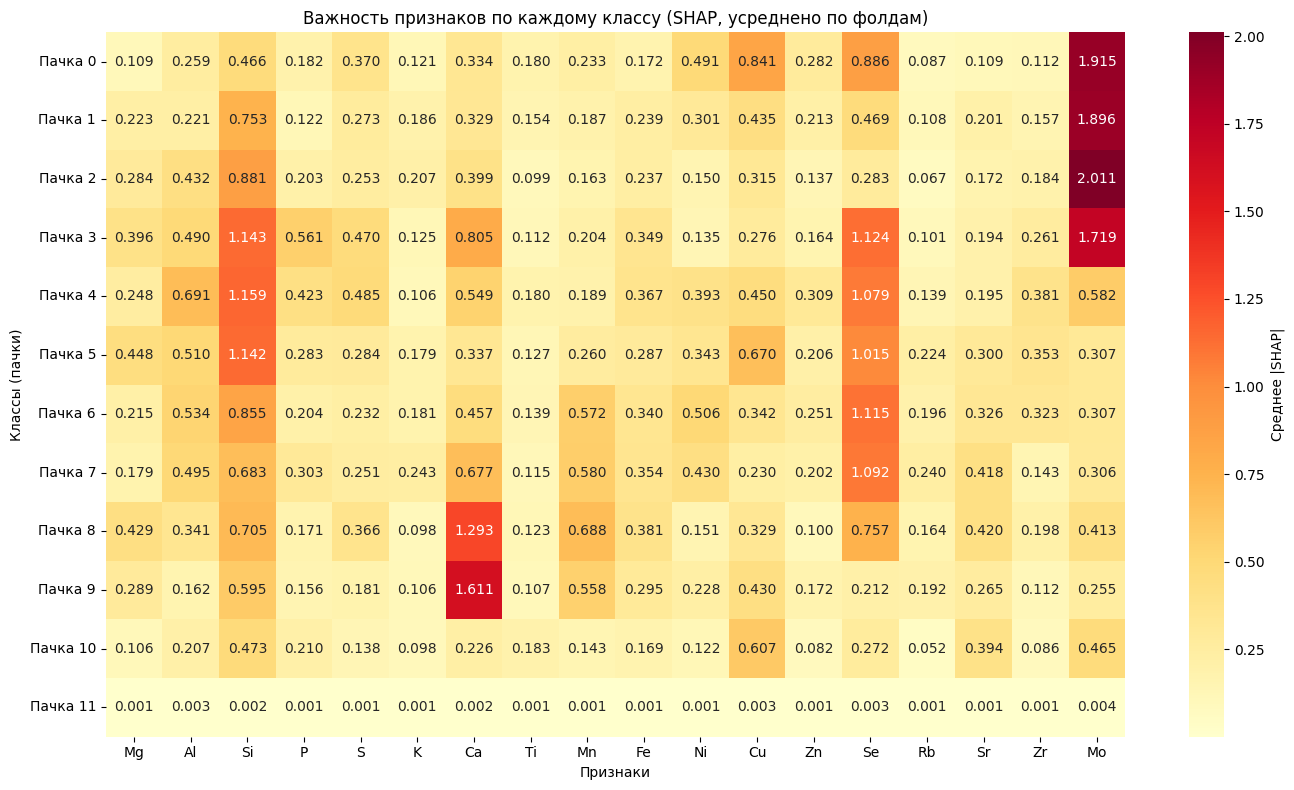

Пачка 0:
  Mo: 1.915
  Se: 0.886
  Cu: 0.841
  Ni: 0.491
  Si: 0.466
  S: 0.370
  Ca: 0.334
  Zn: 0.282
  Al: 0.259
  Mn: 0.233
  P: 0.182
  Ti: 0.180
  Fe: 0.172
  K: 0.121
  Zr: 0.112
  Sr: 0.109
  Mg: 0.109

Пачка 1:
  Mo: 1.896
  Si: 0.753
  Se: 0.469
  Cu: 0.435
  Ca: 0.329
  Ni: 0.301
  S: 0.273
  Fe: 0.239
  Mg: 0.223
  Al: 0.221
  Zn: 0.213
  Sr: 0.201
  Mn: 0.187
  K: 0.186
  Zr: 0.157
  Ti: 0.154
  P: 0.122
  Rb: 0.108

Пачка 2:
  Mo: 2.011
  Si: 0.881
  Al: 0.432
  Ca: 0.399
  Cu: 0.315
  Mg: 0.284
  Se: 0.283
  S: 0.253
  Fe: 0.237
  K: 0.207
  P: 0.203
  Zr: 0.184
  Sr: 0.172
  Mn: 0.163
  Ni: 0.150
  Zn: 0.137

Пачка 3:
  Mo: 1.719
  Si: 1.143
  Se: 1.124
  Ca: 0.805
  P: 0.561
  Al: 0.490
  S: 0.470
  Mg: 0.396
  Fe: 0.349
  Cu: 0.276
  Zr: 0.261
  Mn: 0.204
  Sr: 0.194
  Zn: 0.164
  Ni: 0.135
  K: 0.125
  Ti: 0.112
  Rb: 0.101

Пачка 4:
  Si: 1.159
  Se: 1.079
  Al: 0.691
  Mo: 0.582
  Ca: 0.549
  S: 0.485
  Cu: 0.450
  P: 0.423
  Ni: 0.393
  Zr: 0.381
  Fe: 0.367
  Zn:

/tmp/ipykernel_310122/3787803024.py:168: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

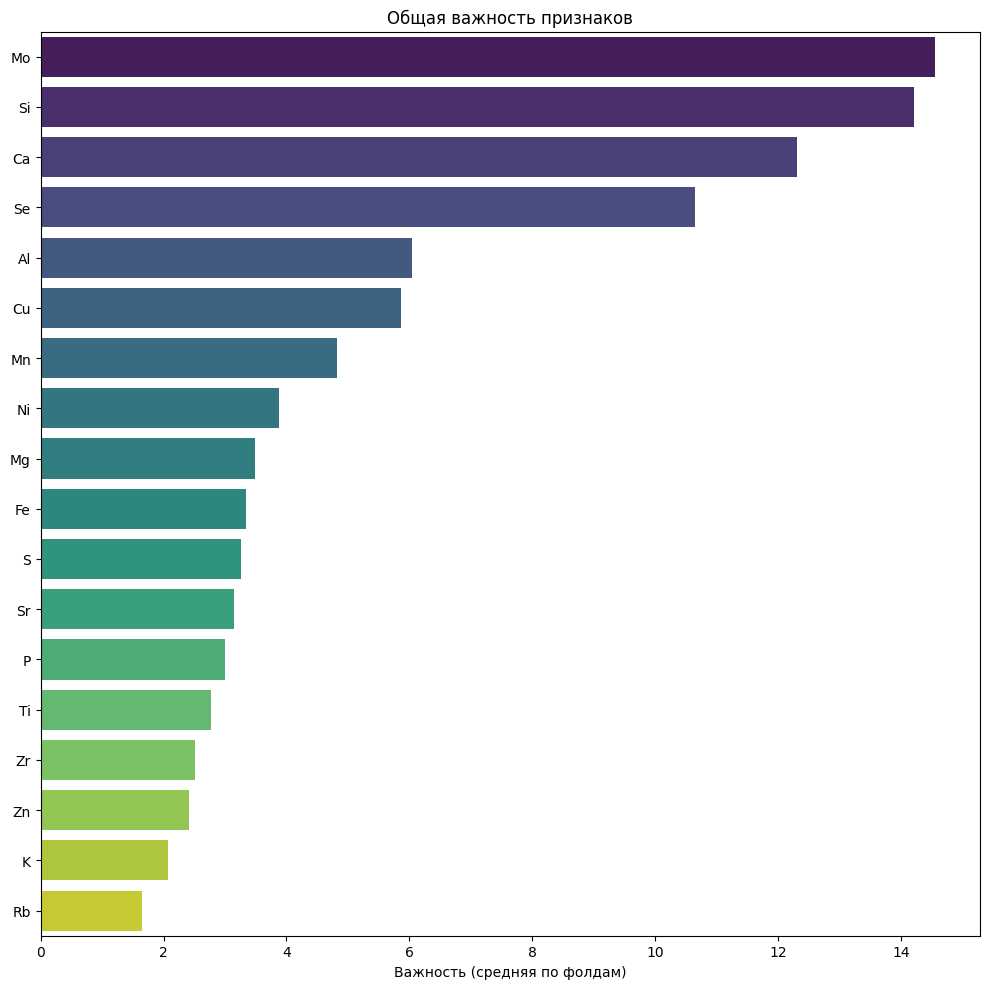

In [9]:
X = df[elements]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42, 
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []
gaps = [] 

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)
    gaps.append(gap)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
#results_df = pd.concat(results_df_list, ignore_index=True)
#results_df.to_csv('Result/classification_results_CatBoost_fixed_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")

print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}")
print(f"  Средний gap: {np.mean(gaps):.4f} ± {np.std(gaps, ddof=1):.4f}")   # ← добавить

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# SHAP: важность по классам (усреднённая по всем фолдам)
# Объединяем SHAP всех фолдов
shap_concat = np.concatenate(shap_all, axis=0)  # (total_samples, n_classes, n_features)
mean_shap = np.abs(shap_concat).mean(axis=0)     # (n_classes, n_features)

plt.figure(figsize=(14, 8))
sns.heatmap(
    mean_shap,
    annot=True, fmt='.3f',
    cmap='YlOrRd',
    xticklabels=elements,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Среднее |SHAP|'}
)
plt.xlabel('Признаки')
plt.ylabel('Классы (пачки)')
plt.title('Важность признаков по каждому классу (SHAP, усреднено по фолдам)')
plt.tight_layout()
plt.show()

# Топ-признаки для каждого класса
for i in range(mean_shap.shape[0]):
    significant = [(elements[j], mean_shap[i, j])
                   for j in range(len(elements))
                   if mean_shap[i, j] > 0.1]
    significant.sort(key=lambda x: -x[1])
    print(f"Пачка {i}:")
    for feat, v in significant:
        print(f"  {feat}: {v:.3f}")
    print()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(elements, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Эксперимент 7**

**Отобранные признаки**

In [6]:
ratios = ['(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)',
          'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al',
          'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)',
          'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)',
          'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S',
          'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti',
          '(10*Rb+Ti+10*Zr)/Se*1000']

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по соотношениям элементов**

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9931
F1 macro (val):   0.4200
Gap (train-val):  0.5731

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9474    0.4286    0.5902       126
           1     0.3585    0.3725    0.3654        51
           2     0.3553    0.5870    0.4426        46
           3     0.6447    0.6806    0.6622        72
           4     0.6522    0.6667    0.6593        45
           5     0.0000    0.0000    0.0000         7
           6     0.4643    0.3023    0.3662        43
           7     0.3182    0.1892    0.2373        37
           8     0.2645    0.6400    0.3743        50
           9     0.5253    0.6582    0.5843        79
          10     0.8519    0.3194    0.4646        72
          11     0.3333    0.2632    0.2941        19

    accuracy                    

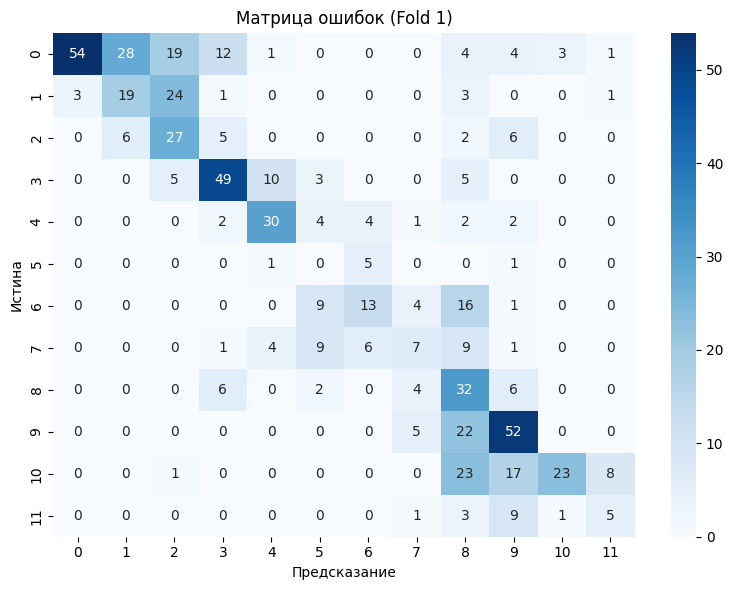

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9917
F1 macro (val):   0.6852
Gap (train-val):  0.3066

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8043    0.9487    0.8706        78
           1     0.8333    0.4545    0.5882        44
           2     0.6275    0.6400    0.6337        50
           3     0.8358    0.7778    0.8058        72
           4     0.6392    0.8052    0.7126        77
           5     0.4545    0.4054    0.4286        37
           6     0.5882    0.3571    0.4444        28
           7     0.5172    0.5357    0.5263        28
           8     0.6951    0.7125    0.7037        80
           9     0.7652    0.8302    0.7964       106
          10     0.9000    0.7500    0.8182        36
          11     0.9130    0.8750    0.8936        24

    accuracy                    

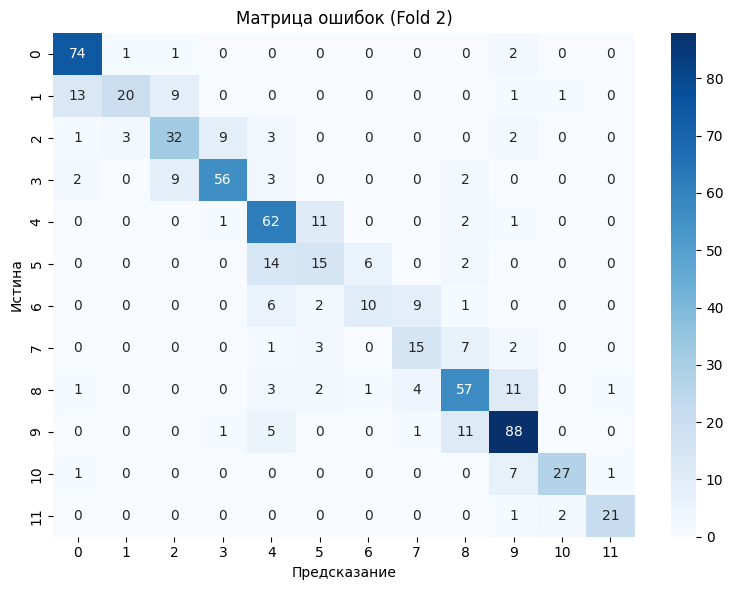

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9956
F1 macro (val):   0.5259
Gap (train-val):  0.4697

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9429    0.9565    0.9496        69
           1     0.3636    0.2857    0.3200        14
           2     0.4444    0.6000    0.5106        40
           3     0.6739    0.6200    0.6458        50
           4     0.7209    0.5741    0.6392        54
           5     0.5789    0.3056    0.4000        36
           6     0.2812    0.5000    0.3600        18
           7     0.4091    0.2368    0.3000        38
           8     0.5806    0.4800    0.5255        75
           9     0.5600    0.8046    0.6604        87
          10     0.4944    0.7213    0.5867        61
          11     0.6061    0.3125    0.4124        64

    accuracy                    

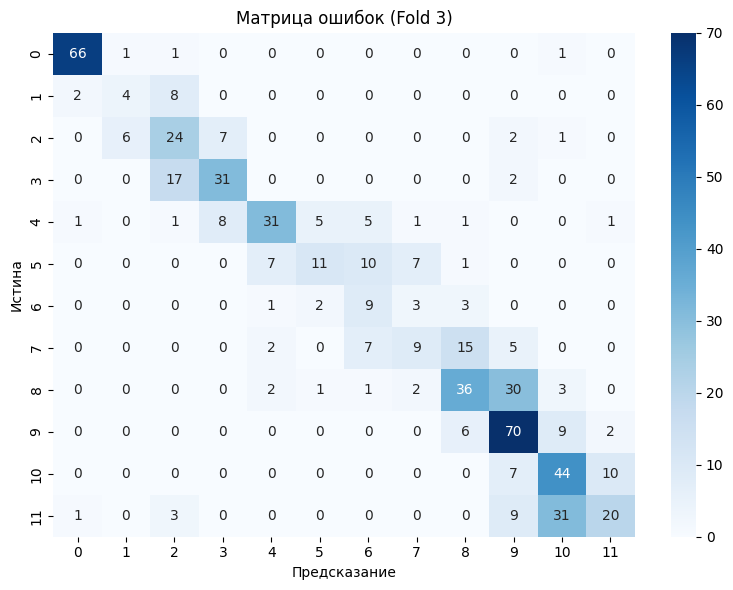

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9923
F1 macro (val):   0.5888
Gap (train-val):  0.4035

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9762    0.8542    0.9111        96
           1     0.7500    0.4737    0.5806        19
           2     0.6857    0.8571    0.7619        28
           3     0.8438    0.8438    0.8438        32
           4     0.5490    0.9032    0.6829        31
           5     0.1212    0.0889    0.1026        45
           6     0.2941    0.1220    0.1724        41
           7     0.2188    0.1167    0.1522        60
           8     0.5573    0.6348    0.5935       115
           9     0.6058    0.7412    0.6667        85
          10     0.6154    0.9302    0.7407        43
          11     1.0000    0.7500    0.8571         4

    accuracy                    

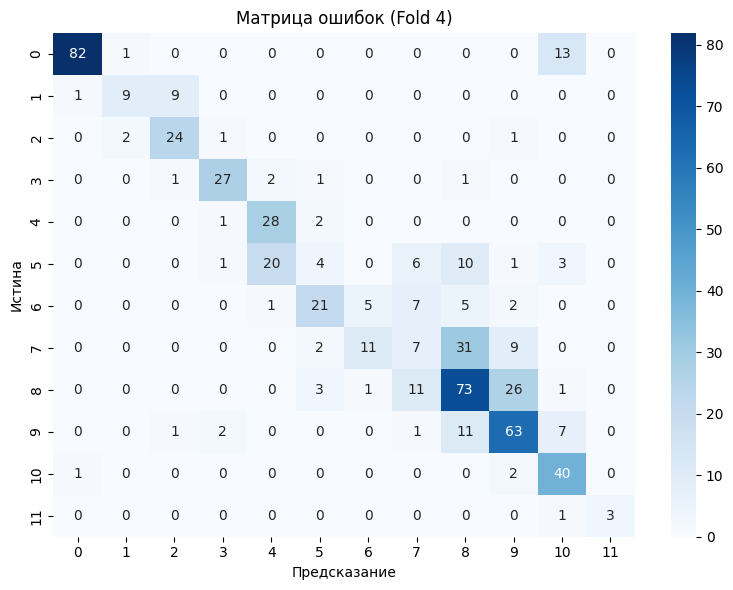

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9910
F1 macro (val):   0.5376
Gap (train-val):  0.4533

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.7297    0.8852    0.8000        61
           1     0.6111    0.4074    0.4889        27
           2     0.4103    0.5517    0.4706        29
           3     0.7826    0.8182    0.8000        44
           4     0.6000    0.8276    0.6957        29
           5     0.2381    0.2500    0.2439        20
           6     0.2308    0.1500    0.1818        20
           7     0.4074    0.3929    0.4000        28
           8     0.4286    0.5417    0.4785        72
           9     0.6434    0.6194    0.6312       134
          10     0.8182    0.4186    0.5538        86
          11     0.6444    0.7838    0.7073        37

    accuracy                    

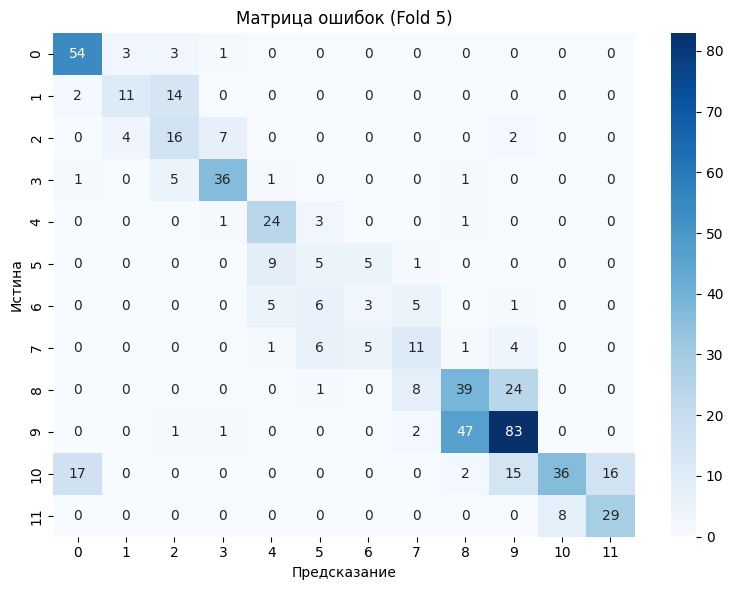

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4200
  Fold 2: F1_macro = 0.6852
  Fold 3: F1_macro = 0.5259
  Fold 4: F1_macro = 0.5888
  Fold 5: F1_macro = 0.5376

  Средний F1 macro: 0.5515 ± 0.0967
  Средний gap: 0.4412 ± 0.0974

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.8753    0.7674    0.8178       430
           1     0.5339    0.4065    0.4615       155
           2     0.4824    0.6373    0.5491       193
           3     0.7453    0.7370    0.7412       270
           4     0.6318    0.7415    0.6823       236
           5     0.2632    0.2414    0.2518       145
           6     0.3738    0.2667    0.3113       150
           7     0.3712    0.2565    0.3034       191
           8     0.4867    0.6046    0.5392       392
           9     0.6224    0.7251    0.6698       491
          10     0.6667    0.5705    0.6148       298
          11     0.6555    0.5270    0.5843       148

    accuracy      

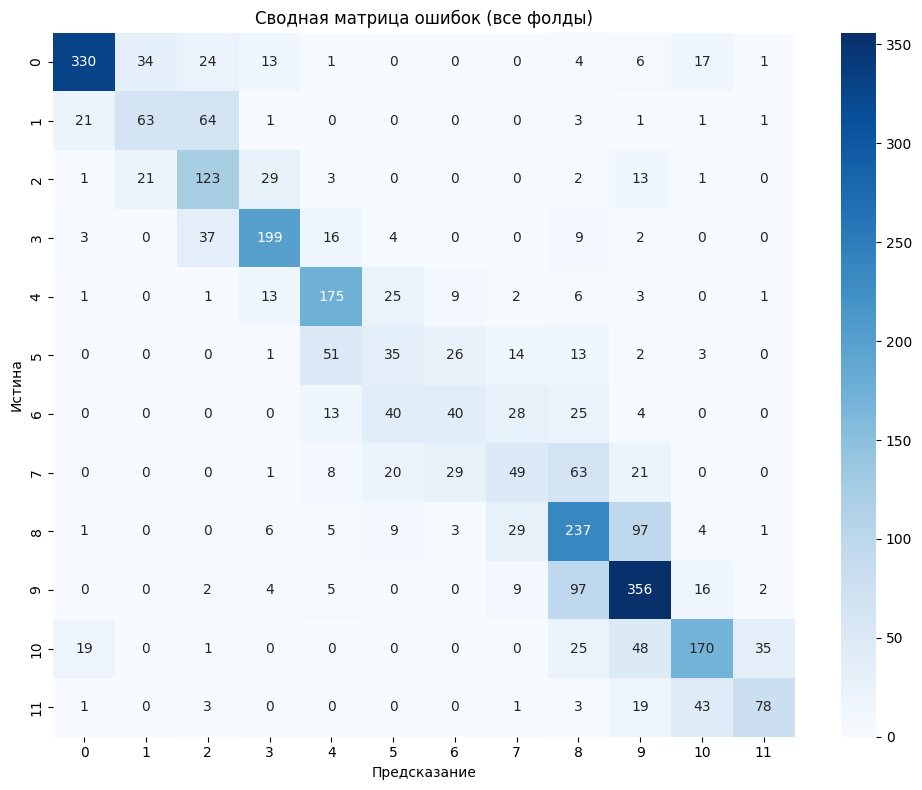

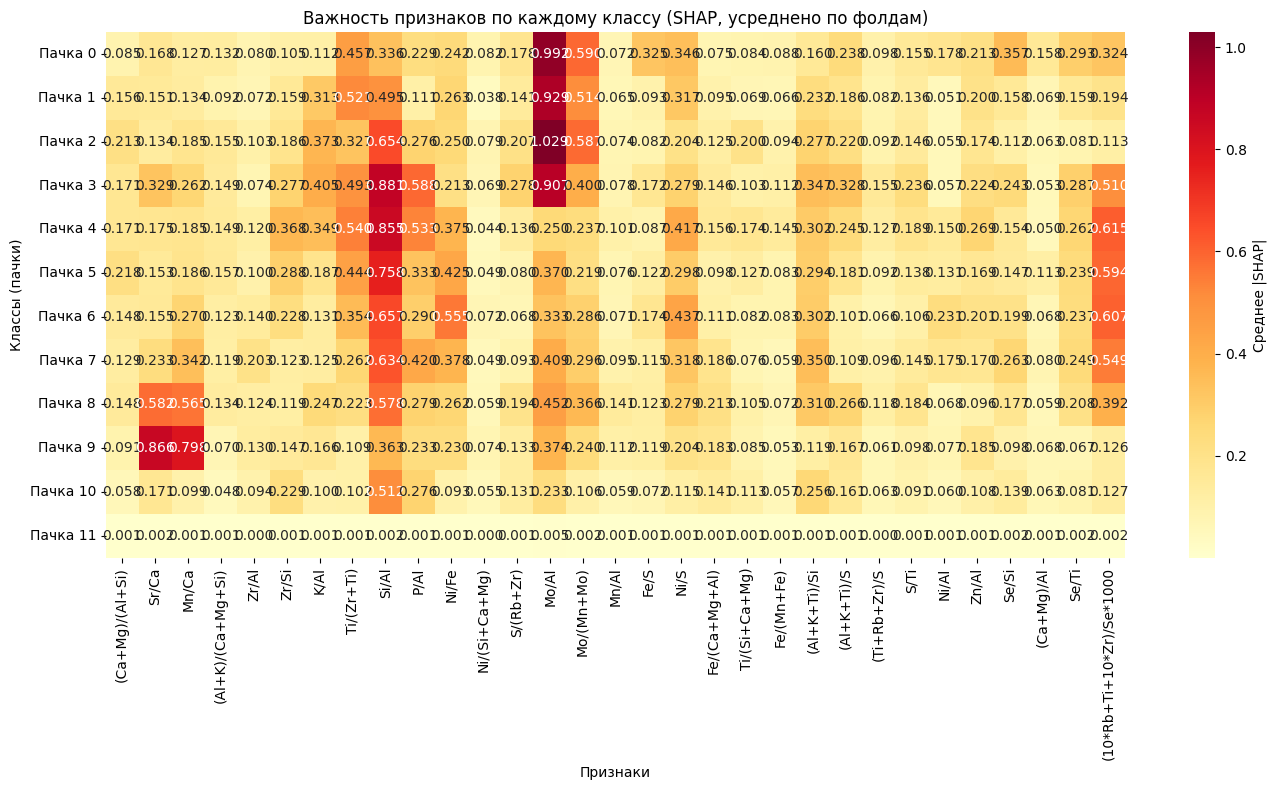

Пачка 0:
  Mo/Al: 0.992
  Mo/(Mn+Mo): 0.590
  Ti/(Zr+Ti): 0.457
  Se/Si: 0.357
  Ni/S: 0.346
  Si/Al: 0.336
  Fe/S: 0.325
  (10*Rb+Ti+10*Zr)/Se*1000: 0.324
  Se/Ti: 0.293
  Ni/Fe: 0.242
  (Al+K+Ti)/S: 0.238
  P/Al: 0.229
  Zn/Al: 0.213
  Ni/Al: 0.178
  S/(Rb+Zr): 0.178
  Sr/Ca: 0.168
  (Al+K+Ti)/Si: 0.160
  (Ca+Mg)/Al: 0.158
  S/Ti: 0.155
  (Al+K)/(Ca+Mg+Si): 0.132
  Mn/Ca: 0.127
  K/Al: 0.112
  Zr/Si: 0.105

Пачка 1:
  Mo/Al: 0.929
  Ti/(Zr+Ti): 0.521
  Mo/(Mn+Mo): 0.514
  Si/Al: 0.495
  Ni/S: 0.317
  K/Al: 0.313
  Ni/Fe: 0.263
  (Al+K+Ti)/Si: 0.232
  Zn/Al: 0.200
  (10*Rb+Ti+10*Zr)/Se*1000: 0.194
  (Al+K+Ti)/S: 0.186
  Zr/Si: 0.159
  Se/Ti: 0.159
  Se/Si: 0.158
  (Ca+Mg)/(Al+Si): 0.156
  Sr/Ca: 0.151
  S/(Rb+Zr): 0.141
  S/Ti: 0.136
  Mn/Ca: 0.134
  P/Al: 0.111

Пачка 2:
  Mo/Al: 1.029
  Si/Al: 0.654
  Mo/(Mn+Mo): 0.587
  K/Al: 0.373
  Ti/(Zr+Ti): 0.327
  (Al+K+Ti)/Si: 0.277
  P/Al: 0.276
  Ni/Fe: 0.250
  (Al+K+Ti)/S: 0.220
  (Ca+Mg)/(Al+Si): 0.213
  S/(Rb+Zr): 0.207
  Ni/S: 0.204
  

/tmp/ipykernel_310122/2795789242.py:168: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

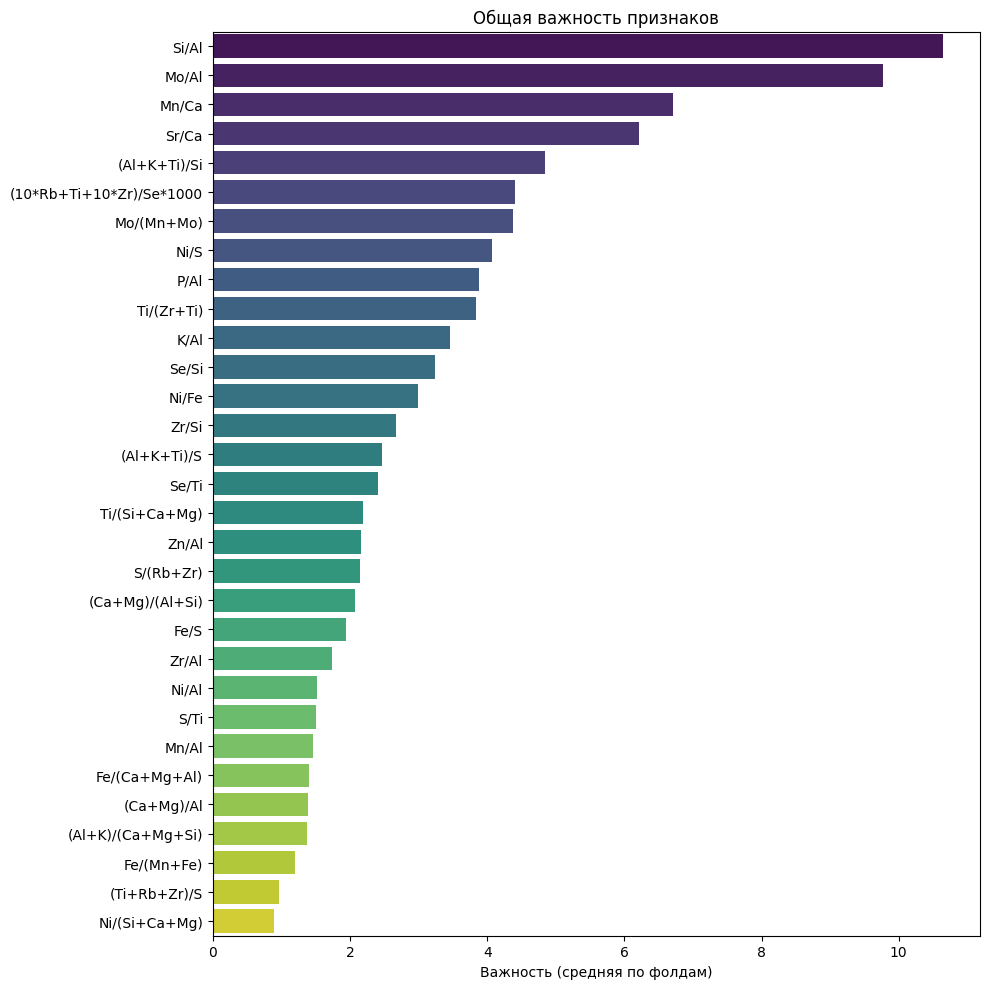

In [7]:
X = df[ratios]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42, 
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []
gaps = [] 

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)
    gaps.append(gap)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
results_df = pd.concat(results_df_list, ignore_index=True)
results_df.to_csv('Result/classification_results_CatBoost_fixed_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")

print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}")
print(f"  Средний gap: {np.mean(gaps):.4f} ± {np.std(gaps, ddof=1):.4f}")  

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# SHAP: важность по классам (усреднённая по всем фолдам)
# Объединяем SHAP всех фолдов
shap_concat = np.concatenate(shap_all, axis=0)  # (total_samples, n_classes, n_features)
mean_shap = np.abs(shap_concat).mean(axis=0)     # (n_classes, n_features)

plt.figure(figsize=(14, 8))
sns.heatmap(
    mean_shap,
    annot=True, fmt='.3f',
    cmap='YlOrRd',
    xticklabels=ratios,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Среднее |SHAP|'}
)
plt.xlabel('Признаки')
plt.ylabel('Классы (пачки)')
plt.title('Важность признаков по каждому классу (SHAP, усреднено по фолдам)')
plt.tight_layout()
plt.show()

# Топ-признаки для каждого класса
for i in range(mean_shap.shape[0]):
    significant = [(ratios[j], mean_shap[i, j])
                   for j in range(len(ratios))
                   if mean_shap[i, j] > 0.1]
    significant.sort(key=lambda x: -x[1])
    print(f"Пачка {i}:")
    for feat, v in significant:
        print(f"  {feat}: {v:.3f}")
    print()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(ratios, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Эксперимент 8**

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по элементам и соотношениям элементов**

In [10]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al',
    'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)',
    'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S',
    'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9923
F1 macro (val):   0.4525
Gap (train-val):  0.5398

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9667    0.4603    0.6237       126
           1     0.3636    0.3922    0.3774        51
           2     0.3000    0.6522    0.4110        46
           3     0.6585    0.7500    0.7013        72
           4     0.6458    0.6889    0.6667        45
           5     0.0000    0.0000    0.0000         7
           6     0.4359    0.3953    0.4146        43
           7     0.3333    0.2162    0.2623        37
           8     0.3134    0.4200    0.3590        50
           9     0.5900    0.7468    0.6592        79
          10     0.9375    0.4167    0.5769        72
          11     0.3889    0.3684    0.3784        19

    accuracy                    

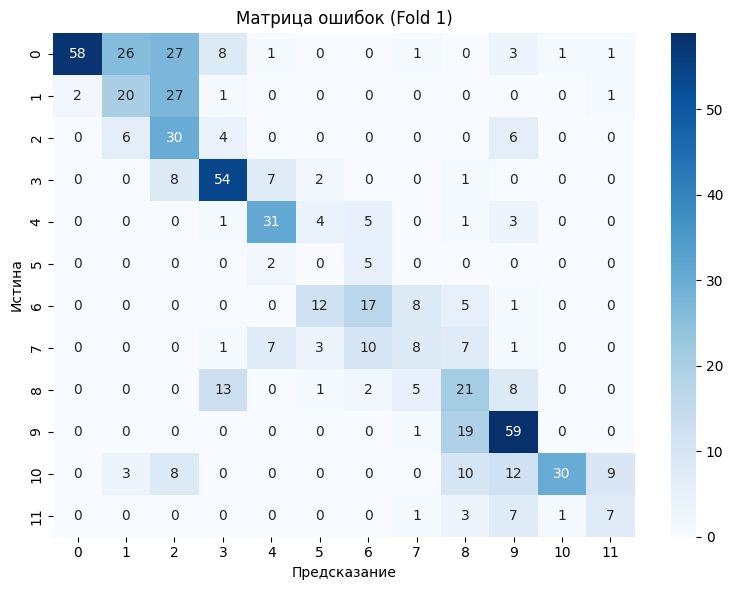

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9937
F1 macro (val):   0.6703
Gap (train-val):  0.3234

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8065    0.9615    0.8772        78
           1     0.7308    0.4318    0.5429        44
           2     0.6038    0.6400    0.6214        50
           3     0.8281    0.7361    0.7794        72
           4     0.6200    0.8052    0.7006        77
           5     0.5238    0.2973    0.3793        37
           6     0.4444    0.2857    0.3478        28
           7     0.4857    0.6071    0.5397        28
           8     0.6742    0.7500    0.7101        80
           9     0.7830    0.7830    0.7830       106
          10     0.8529    0.8056    0.8286        36
          11     1.0000    0.8750    0.9333        24

    accuracy                    

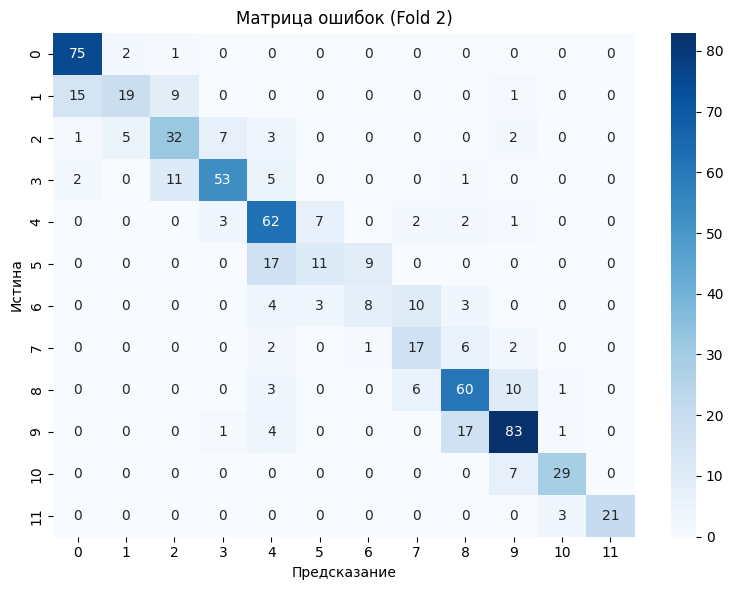

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9945
F1 macro (val):   0.5396
Gap (train-val):  0.4549

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9571    0.9710    0.9640        69
           1     0.3333    0.2857    0.3077        14
           2     0.4423    0.5750    0.5000        40
           3     0.6957    0.6400    0.6667        50
           4     0.7045    0.5741    0.6327        54
           5     0.5714    0.3333    0.4211        36
           6     0.3077    0.4444    0.3636        18
           7     0.4091    0.2368    0.3000        38
           8     0.5634    0.5333    0.5479        75
           9     0.5946    0.7586    0.6667        87
          10     0.5111    0.7541    0.6093        61
          11     0.6341    0.4062    0.4952        64

    accuracy                    

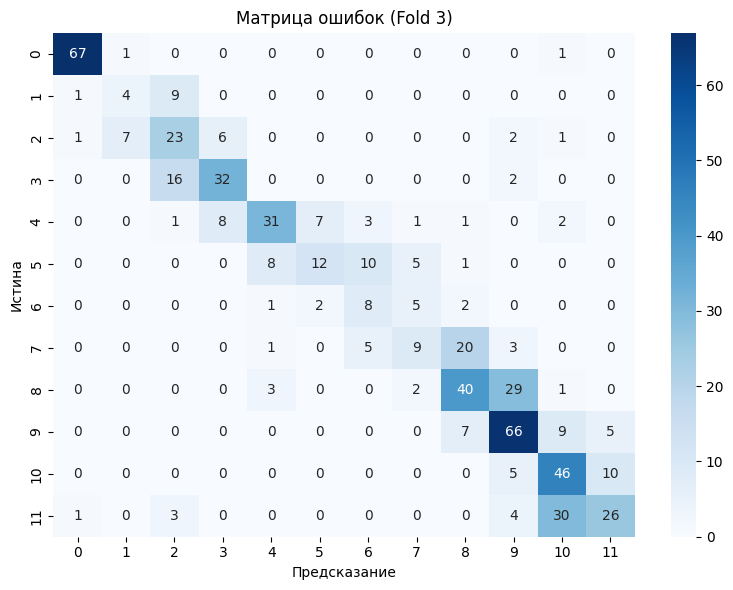

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9926
F1 macro (val):   0.6173
Gap (train-val):  0.3753

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9894    0.9688    0.9789        96
           1     0.6923    0.4737    0.5625        19
           2     0.6857    0.8571    0.7619        28
           3     0.8485    0.8750    0.8615        32
           4     0.5200    0.8387    0.6420        31
           5     0.2286    0.1778    0.2000        45
           6     0.3529    0.1463    0.2069        41
           7     0.2727    0.1500    0.1935        60
           8     0.5556    0.6087    0.5809       115
           9     0.6355    0.8000    0.7083        85
          10     0.7736    0.9535    0.8542        43
          11     1.0000    0.7500    0.8571         4

    accuracy                    

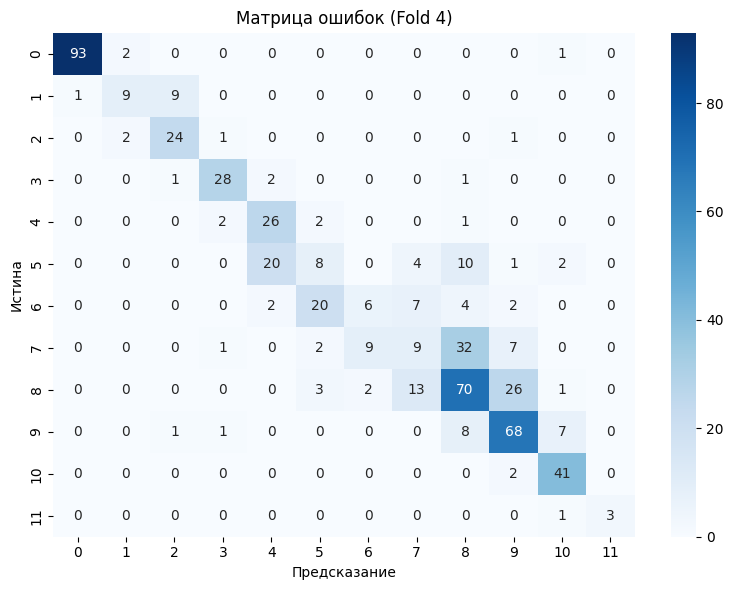

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9893
F1 macro (val):   0.5707
Gap (train-val):  0.4186

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8235    0.9180    0.8682        61
           1     0.6000    0.4444    0.5106        27
           2     0.4054    0.5172    0.4545        29
           3     0.8182    0.8182    0.8182        44
           4     0.7027    0.8966    0.7879        29
           5     0.3333    0.4000    0.3636        20
           6     0.2000    0.1000    0.1333        20
           7     0.3448    0.3571    0.3509        28
           8     0.4130    0.5278    0.4634        72
           9     0.6515    0.6418    0.6466       134
          10     0.8704    0.5465    0.6714        86
          11     0.7500    0.8108    0.7792        37

    accuracy                    

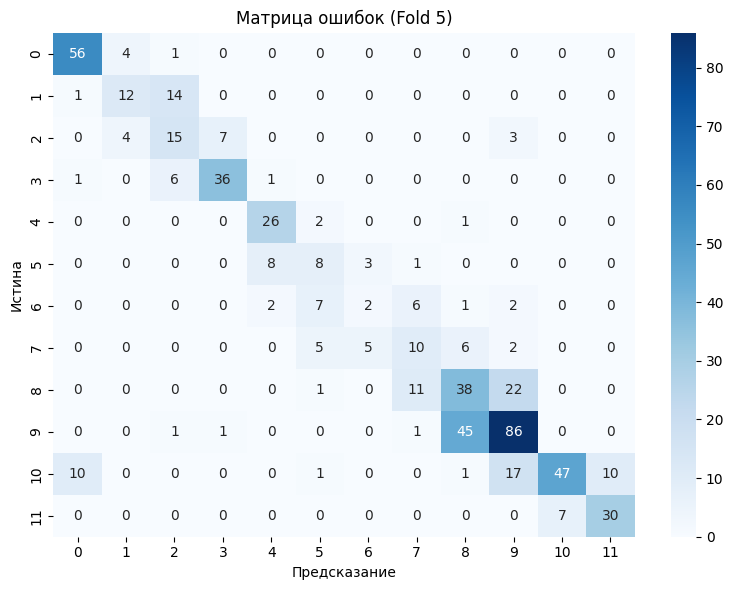

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4525
  Fold 2: F1_macro = 0.6703
  Fold 3: F1_macro = 0.5396
  Fold 4: F1_macro = 0.6173
  Fold 5: F1_macro = 0.5707

  Средний F1 macro: 0.5701 ± 0.0735

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9065    0.8116    0.8564       430
           1     0.5079    0.4129    0.4555       155
           2     0.4477    0.6425    0.5277       193
           3     0.7546    0.7519    0.7532       270
           4     0.6308    0.7458    0.6835       236
           5     0.3171    0.2690    0.2910       145
           6     0.3727    0.2733    0.3154       150
           7     0.3706    0.2775    0.3174       191
           8     0.5146    0.5842    0.5472       392
           9     0.6511    0.7373    0.6915       491
          10     0.7338    0.6477    0.6881       298
          11     0.7073    0.5878    0.6421       148

    accuracy                         0.6196      

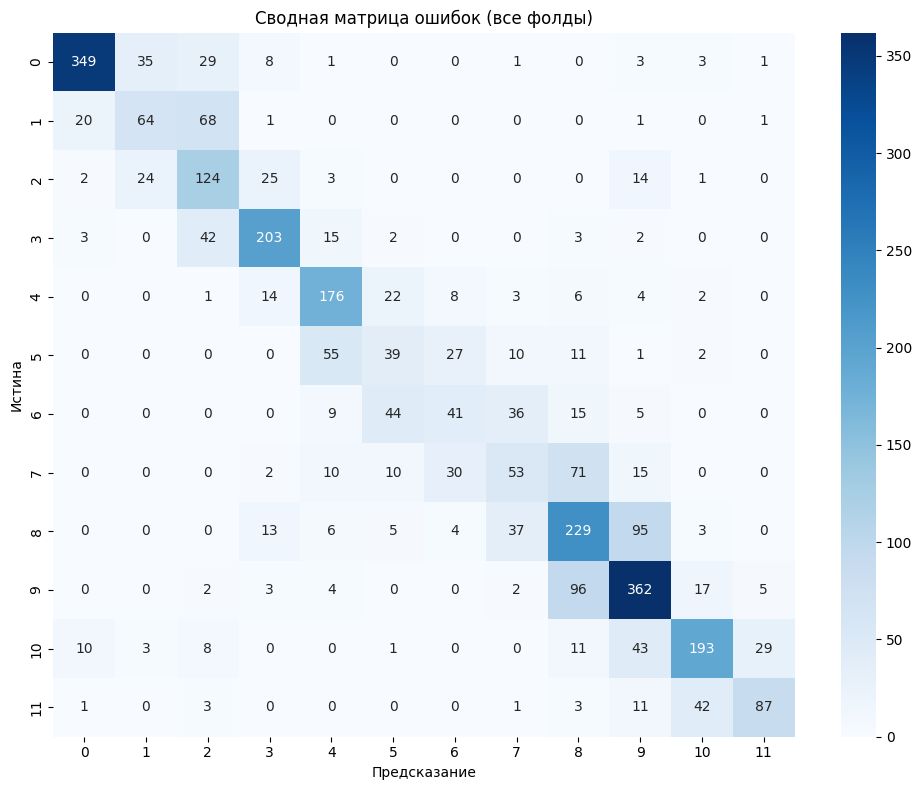

/tmp/ipykernel_310122/2287251422.py:136: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

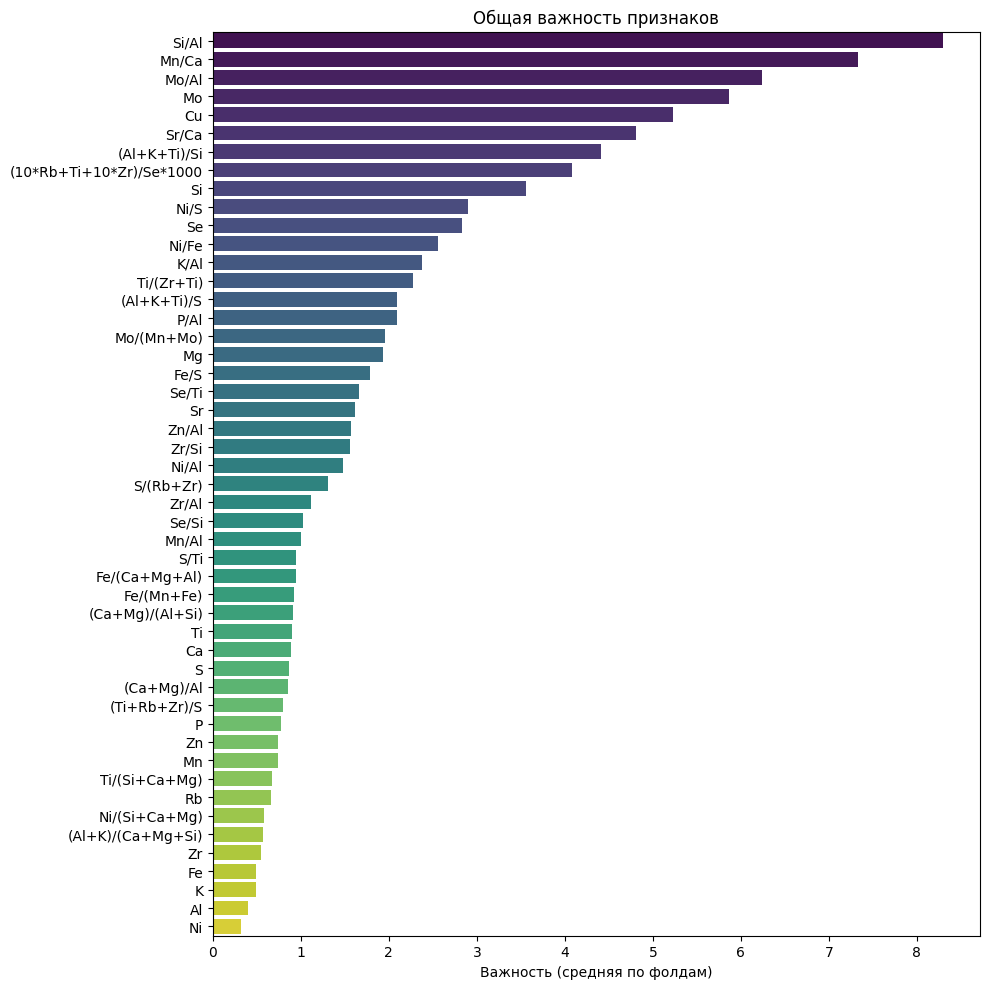

In [11]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []
gaps = [] 

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)
    gaps.append(gap)


    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
#results_df = pd.concat(results_df_list, ignore_index=True)
#results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

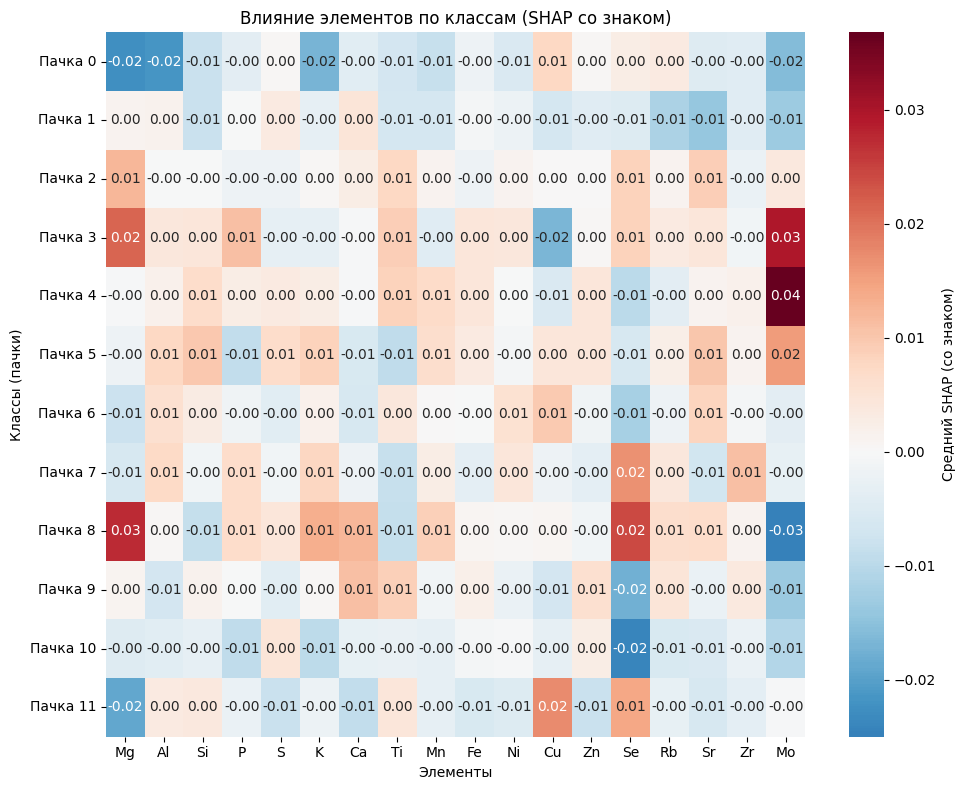

Пачка 0:
  ↓ Mg: -0.023
  ↓ Al: -0.022
  ↓ K: -0.017
  ↓ Mo: -0.016

Пачка 1:
  ↓ Sr: -0.014
  ↓ Mo: -0.013
  ↓ Rb: -0.012

Пачка 2:
  ↑ Mg: +0.012

Пачка 3:
  ↑ Mo: +0.030
  ↑ Mg: +0.021
  ↓ Cu: -0.017
  ↑ P: +0.011

Пачка 4:
  ↑ Mo: +0.037

Пачка 5:
  ↑ Mo: +0.016
  ↑ Sr: +0.010

Пачка 6:
  ↓ Se: -0.012

Пачка 7:
  ↑ Se: +0.017
  ↑ Zr: +0.011

Пачка 8:
  ↑ Mg: +0.027
  ↓ Mo: -0.025
  ↑ Se: +0.024
  ↑ K: +0.013
  ↑ Ca: +0.012

Пачка 9:
  ↓ Se: -0.018
  ↓ Mo: -0.014
  ↑ Ca: +0.011

Пачка 10:
  ↓ Se: -0.024
  ↓ Mo: -0.011

Пачка 11:
  ↓ Mg: -0.019
  ↑ Cu: +0.017
  ↑ Se: +0.014



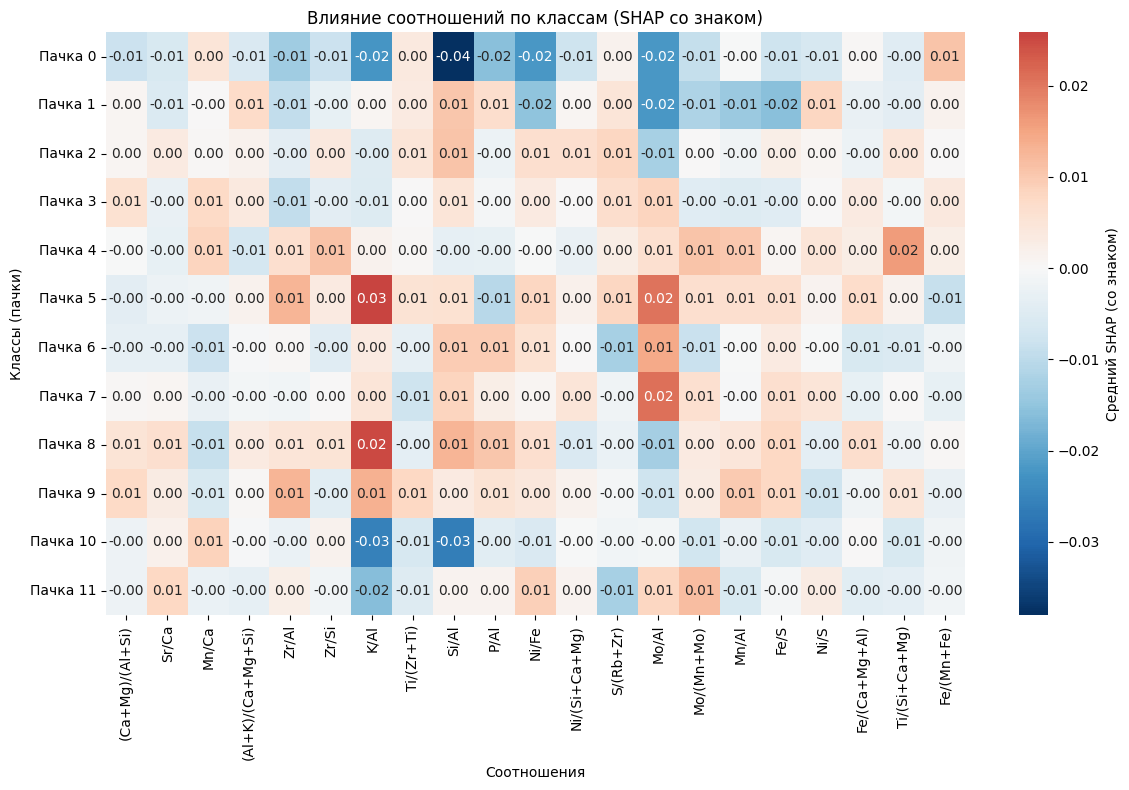

Пачка 0:
  ↓ Si/Al: -0.038
  ↓ K/Al: -0.022
  ↓ Ni/Fe: -0.022
  ↓ Mo/Al: -0.022
  ↓ P/Al: -0.016
  ↓ Zr/Al: -0.014
  ↑ Fe/(Mn+Fe): +0.011

Пачка 1:
  ↓ Mo/Al: -0.022
  ↓ Fe/S: -0.016
  ↓ Ni/Fe: -0.015
  ↓ Mn/Al: -0.014
  ↓ Mo/(Mn+Mo): -0.012
  ↑ Si/Al: +0.011

Пачка 2:
  ↓ Mo/Al: -0.013
  ↑ Si/Al: +0.011

Пачка 3:

Пачка 4:
  ↑ Ti/(Si+Ca+Mg): +0.016
  ↑ Zr/Si: +0.011
  ↑ Mo/(Mn+Mo): +0.011
  ↑ Mn/Al: +0.010

Пачка 5:
  ↑ K/Al: +0.026
  ↑ Mo/Al: +0.020
  ↑ Zr/Al: +0.013
  ↓ P/Al: -0.010

Пачка 6:
  ↑ Mo/Al: +0.014
  ↓ S/(Rb+Zr): -0.013

Пачка 7:
  ↑ Mo/Al: +0.021

Пачка 8:
  ↑ K/Al: +0.025
  ↓ Mo/Al: -0.013
  ↑ Si/Al: +0.013
  ↑ P/Al: +0.010

Пачка 9:
  ↑ K/Al: +0.013
  ↑ Zr/Al: +0.013
  ↑ Mn/Al: +0.010

Пачка 10:
  ↓ Si/Al: -0.026
  ↓ K/Al: -0.026

Пачка 11:
  ↓ K/Al: -0.016
  ↓ S/(Rb+Zr): -0.013
  ↑ Mo/(Mn+Mo): +0.012



In [46]:
# SHAP со знаком, разделённый на элементы и соотношения
shap_concat = np.concatenate(shap_all, axis=0)  
mean_shap = shap_concat.mean(axis=0)             

elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

ratios = ['(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca',
          '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)',
          'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)',
          'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
          'Fe/S', 'Ni/S',
          'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)']

elem_idx = [features.index(e) for e in elements]
ratio_idx = [features.index(r) for r in ratios]

mean_shap_elem = mean_shap[:, elem_idx]    # (n_classes, n_elements)
mean_shap_ratio = mean_shap[:, ratio_idx]  # (n_classes, n_ratios)

# Таблица 1: Элементы
plt.figure(figsize=(10, 8))
sns.heatmap(
    mean_shap_elem,
    annot=True, fmt='.2f',
    cmap='RdBu_r',
    center=0,
    xticklabels=elements,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Средний SHAP (со знаком)'}
)
plt.xlabel('Элементы')
plt.ylabel('Классы (пачки)')
plt.title('Влияние элементов по классам (SHAP со знаком)')
plt.tight_layout()
plt.show()

# Вывод топ-элементов по пачкам
for i in range(mean_shap_elem.shape[0]):
    significant = [(elements[j], mean_shap_elem[i, j])
                   for j in range(len(elements))
                   if abs(mean_shap_elem[i, j]) > 0.01]
    significant.sort(key=lambda x: -abs(x[1]))
    print(f"Пачка {i}:")
    for feat, v in significant:
        direction = "↑" if v > 0 else "↓"
        print(f"  {direction} {feat}: {v:+.3f}")
    print()

# Таблица 2: Соотношения
plt.figure(figsize=(12, 8))
sns.heatmap(
    mean_shap_ratio,
    annot=True, fmt='.2f',
    cmap='RdBu_r',
    center=0,
    xticklabels=ratios,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Средний SHAP (со знаком)'}
)
plt.xlabel('Соотношения')
plt.ylabel('Классы (пачки)')
plt.title('Влияние соотношений по классам (SHAP со знаком)')
plt.tight_layout()
plt.show()

# Вывод топ-соотношений по пачкам
for i in range(mean_shap_ratio.shape[0]):
    significant = [(ratios[j], mean_shap_ratio[i, j])
                   for j in range(len(ratios))
                   if abs(mean_shap_ratio[i, j]) > 0.01]
    significant.sort(key=lambda x: -abs(x[1]))
    print(f"Пачка {i}:")
    for feat, v in significant:
        direction = "↑" if v > 0 else "↓"
        print(f"  {direction} {feat}: {v:+.3f}")
    print()


In [47]:
threshold = 0.01

# Элементы, где |SHAP| < 0.01 во всех пачках
weak_elems = [e for e, col in zip(elements, mean_shap_elem.T) if np.all(np.abs(col) < threshold)]

# Соотношения, где |SHAP| < 0.01 во всех пачках
weak_ratios = [r for r, col in zip(ratios, mean_shap_ratio.T) if np.all(np.abs(col) < threshold)]

print("Элементы:", weak_elems)
print("Соотношения:", weak_ratios)


Элементы: ['Si', 'S', 'Ti', 'Mn', 'Fe', 'Ni', 'Zn']
Соотношения: ['(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Ti/(Zr+Ti)', 'Ni/(Si+Ca+Mg)', 'Ni/S', 'Fe/(Ca+Mg+Al)']


**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по элементам и соотношениям элементов. Только по наиболее важным признакам**

In [48]:
features = [
    'Mg', 'Al', 'P', 'K', 'Ca',
    'Cu', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    'Zr/Al', 'Zr/Si', 'K/Al',
    'Si/Al', 'P/Al', 'Ni/Fe', 
    'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2452 проб, Val: 647 проб
F1 macro (train): 0.9871
F1 macro (val):   0.4384
Gap (train-val):  0.5487

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9444    0.5397    0.6869       126
           1     0.4118    0.2745    0.3294        51
           2     0.2600    0.5652    0.3562        46
           3     0.7143    0.6944    0.7042        72
           4     0.5435    0.5556    0.5495        45
           5     0.0000    0.0000    0.0000         7
           6     0.4091    0.4186    0.4138        43
           7     0.3182    0.1892    0.2373        37
           8     0.2824    0.4800    0.3556        50
           9     0.5728    0.7468    0.6484        79
          10     0.8333    0.4167    0.5556        72
          11     0.5000    0.3684    0.4242        19

    accuracy                    

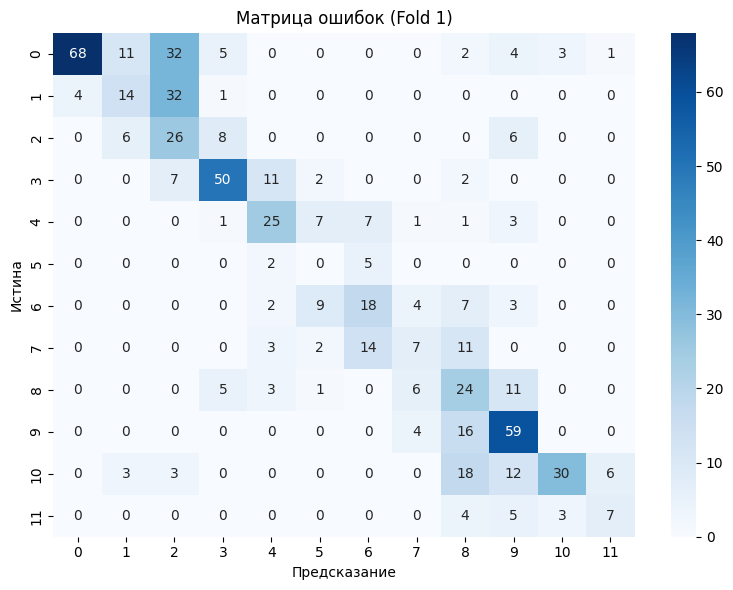

Fold 2
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A3', 'C2', 'C7']
  Train: 2439 проб, Val: 660 проб
F1 macro (train): 0.9884
F1 macro (val):   0.6630
Gap (train-val):  0.3255

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8111    0.9359    0.8690        78
           1     0.7037    0.4318    0.5352        44
           2     0.6038    0.6400    0.6214        50
           3     0.8088    0.7639    0.7857        72
           4     0.6364    0.8182    0.7159        77
           5     0.5357    0.4054    0.4615        37
           6     0.5000    0.2143    0.3000        28
           7     0.3529    0.4286    0.3871        28
           8     0.6042    0.7250    0.6591        80
           9     0.8144    0.7453    0.7783       106
          10     0.9118    0.8611    0.8857        36
          11     1.0000    0.9167    0.9565        24

    accuracy                    

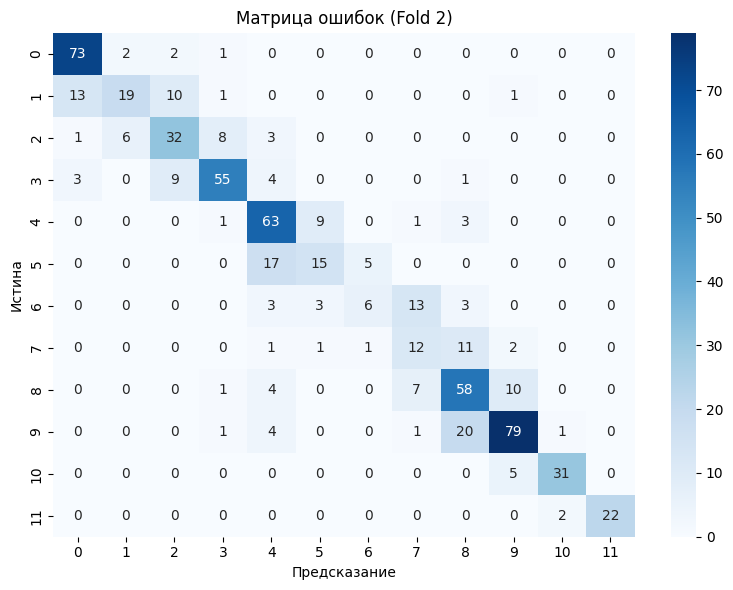

Fold 3
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C2', 'C3', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['B1', 'C1', 'C4']
  Train: 2493 проб, Val: 606 проб
F1 macro (train): 0.9915
F1 macro (val):   0.5362
Gap (train-val):  0.4553

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9565    0.9565    0.9565        69
           1     0.2727    0.2143    0.2400        14
           2     0.4545    0.6250    0.5263        40
           3     0.6327    0.6200    0.6263        50
           4     0.7838    0.5370    0.6374        54
           5     0.6522    0.4167    0.5085        36
           6     0.3226    0.5556    0.4082        18
           7     0.3889    0.1842    0.2500        38
           8     0.5694    0.5467    0.5578        75
           9     0.6034    0.8046    0.6897        87
          10     0.5000    0.7541    0.6013        61
          11     0.6364    0.3281    0.4330        64

    accuracy                    

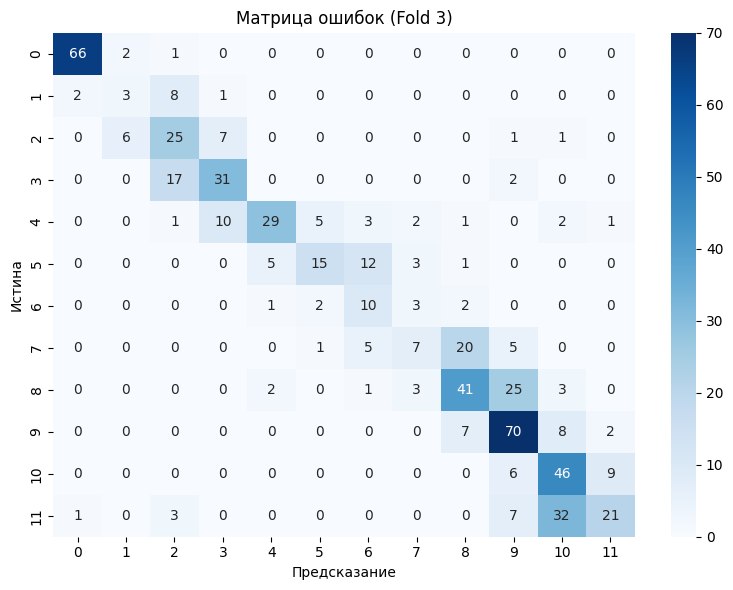

Fold 4
  Train wells: ['A1', 'A3', 'B1', 'C1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'A4', 'C5']
  Train: 2500 проб, Val: 599 проб
F1 macro (train): 0.9851
F1 macro (val):   0.6263
Gap (train-val):  0.3588

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9789    0.9688    0.9738        96
           1     0.8462    0.5789    0.6875        19
           2     0.7059    0.8571    0.7742        28
           3     0.8485    0.8750    0.8615        32
           4     0.5217    0.7742    0.6234        31
           5     0.2632    0.2222    0.2410        45
           6     0.3529    0.1463    0.2069        41
           7     0.2353    0.1333    0.1702        60
           8     0.5447    0.5826    0.5630       115
           9     0.6126    0.8000    0.6939        85
          10     0.7885    0.9535    0.8632        43
          11     1.0000    0.7500    0.8571         4

    accuracy                    

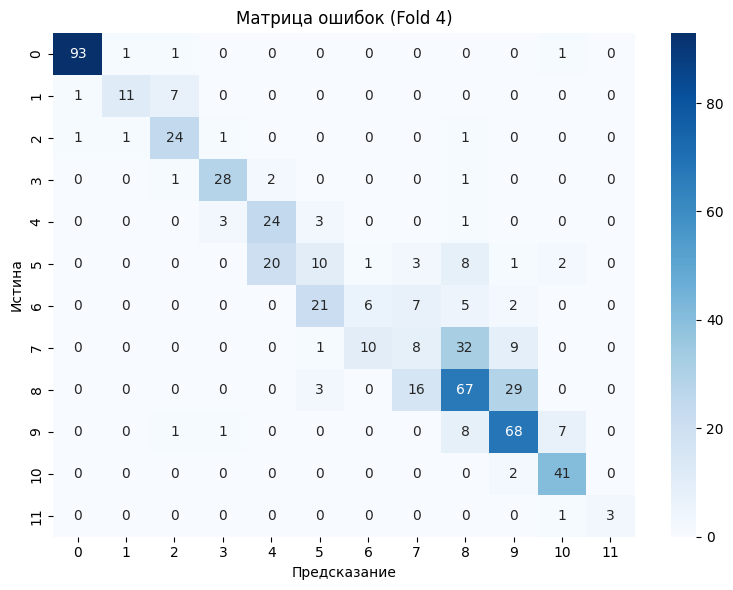

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C4', 'C5', 'C7', 'E1']
  Val wells:   ['C3', 'C6', 'D1']
  Train: 2512 проб, Val: 587 проб
F1 macro (train): 0.9835
F1 macro (val):   0.5657
Gap (train-val):  0.4178

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.8261    0.9344    0.8769        61
           1     0.6316    0.4444    0.5217        27
           2     0.4474    0.5862    0.5075        29
           3     0.8605    0.8409    0.8506        44
           4     0.6286    0.7586    0.6875        29
           5     0.3182    0.3500    0.3333        20
           6     0.2000    0.1500    0.1714        20
           7     0.3200    0.2857    0.3019        28
           8     0.4409    0.5694    0.4970        72
           9     0.6538    0.6343    0.6439       134
          10     0.8393    0.5465    0.6620        86
          11     0.6905    0.7838    0.7342        37

    accuracy                    

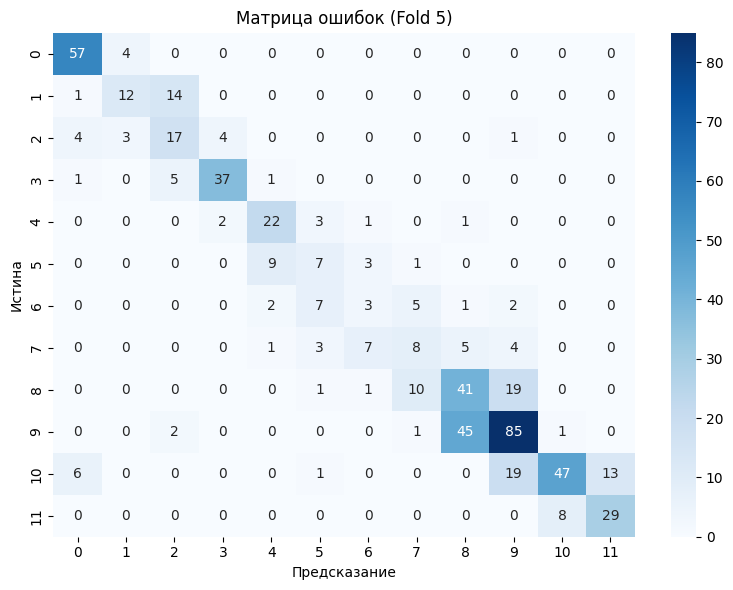

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4384
  Fold 2: F1_macro = 0.6630
  Fold 3: F1_macro = 0.5362
  Fold 4: F1_macro = 0.6263
  Fold 5: F1_macro = 0.5657

  Средний F1 macro: 0.5659 ± 0.0777

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9038    0.8302    0.8655       430
           1     0.5673    0.3806    0.4556       155
           2     0.4429    0.6425    0.5243       193
           3     0.7643    0.7444    0.7542       270
           4     0.6198    0.6907    0.6533       236
           5     0.3561    0.3241    0.3394       145
           6     0.3613    0.2867    0.3197       150
           7     0.3158    0.2199    0.2593       191
           8     0.4925    0.5893    0.5366       392
           9     0.6481    0.7352    0.6889       491
          10     0.7222    0.6544    0.6866       298
          11     0.7193    0.5541    0.6260       148

    accuracy                         0.6147      

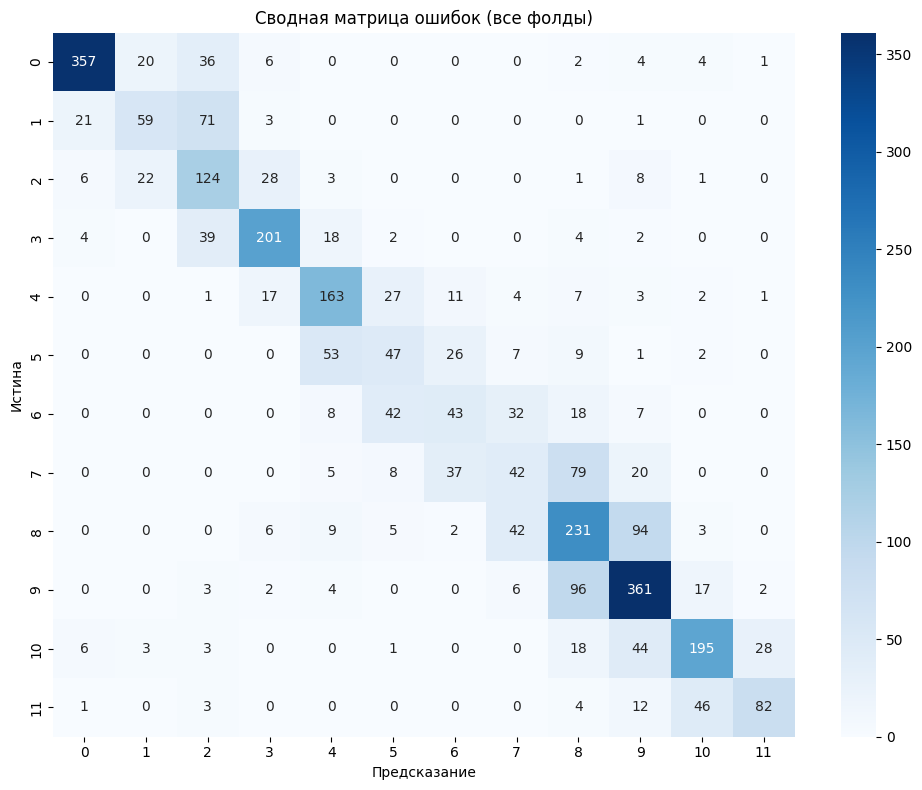

/tmp/ipykernel_375205/2631189579.py:127: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

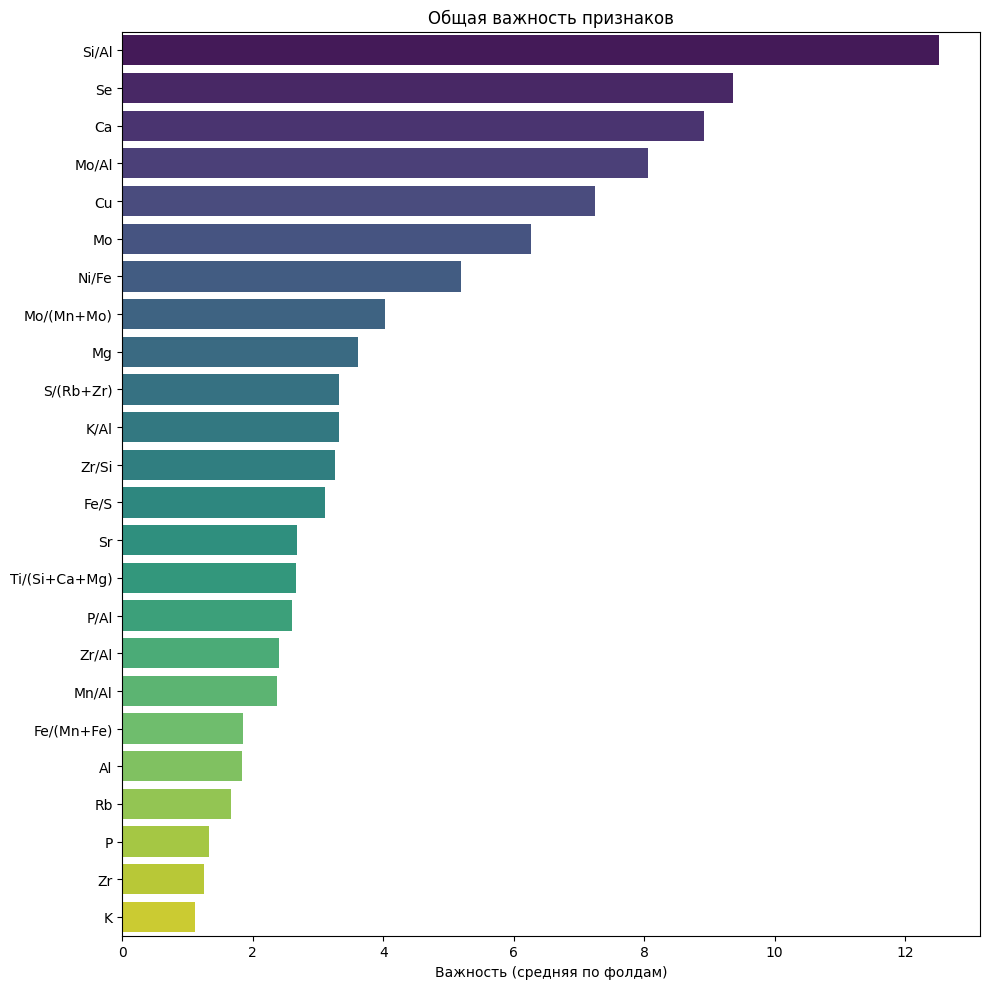

In [49]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")

print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}")
print(f"  Средний gap: {np.mean(gaps):.4f} ± {np.std(gaps, ddof=1):.4f}")  

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Вывод: Удаление слабых признаков не помогло — F1 macro упал на 0.009, переобучение не снизилось.**

**Проблема не в признаках. Три разных набора (18, 39, 30) дают практически одинаковый результат: 0.57 ± 0.02. Переобучение (train 0.98, val 0.57) и провал на Fold 1 (A1, E1) сохраняются во всех случаях.
Корень проблемы — межскважинная вариативность. Модель заучивает паттерны конкретных скважин, а не геохимические сигналы пачек.**